# Hist IRF normalization

Validation of the event-probability normalization of `IRFRelativeHistUnpolarized`
on the real `hist_simple` response (`ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5`).

In an unbinned fit with a dominant background, the likelihood amplifies any mismatch
between the integral of the source density over the selected data space and the
expected counts (the selected effective area): for the 3 h Crab the flux bias is about
10 times the mismatch. So the event probability, *as evaluated* (interpolated between
bin centers), must integrate to exactly 1 over the selected data space, for any photon.

This notebook integrates the conditional event probability numerically over
`Em`, `Phi` and `PsiChi`, for photons between the `Ei` and `NuLambda` bin centers, with
several energy selections, for the previous version of the class (`develop_israel` at
44957037) and the current one. It also shows the new edge treatment: the density ramps
to zero at the `Epsilon` edges, and `Zeta` is periodic.

To keep it light, only 4 `Ei` bins (319-916 keV, around 511 keV) of the 14 GB file are
loaded. Photons are kept between the outer centers of these bins.

In [1]:
import gc
import importlib.util
import subprocess
import tempfile
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.coordinates import CartesianRepresentation, UnitSphericalRepresentation
from histpy import Axes, Axis, Histogram

import cosipy.polarization  # registers the PolarizationAxis class to open the axes
from cosipy.data_io.EmCDSUnbinnedData import EmCDSEventDataInSCFrameFromArrays
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.response.relative_coordinates import RelativeCDSCoordinates
from cosipy.response.photon_types import PhotonListWithDirectionAndEnergyInSCFrame
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
data_path = Path('/home/user/irftest')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'

ei_slice = slice(4, 8)  # Ei bins [319, 404, 510, 600, 917] keV


def load_slice():
    """IRF restricted to a few Ei bins, and the full AEFF, read from disk."""

    with h5py.File(irf_file, 'r') as f:
        axes = Axes.open(f['IRF/axes'])
        contents = f['IRF/contents'][:, ei_slice]

    ei = axes['Ei']
    ei_axis = Axis(ei.edges[ei_slice.start:ei_slice.stop + 1], label='Ei', scale=ei.axis_scale)
    axes = Axes([ei_axis if a.label == 'Ei' else a for a in axes])

    return (Histogram(axes, contents=contents, unit=u.cm ** 2, copy_contents=False),
            Histogram.open(irf_file, 'AEFF'))


irf, aeff = load_slice()
print(irf.axes['Ei'].edges)
print(irf.axes['Epsilon'].edges)

[319.37 403.59 510.   600.   916.89] keV
[-1.     -0.5    -0.41   -0.32   -0.22   -0.13   -0.039  -0.03   -0.016
 -0.01   -0.0057 -0.0018  0.0018  0.0057  0.01    0.016   0.03    0.039
  0.2   ]


The previous version, from git:

In [3]:
def load_previous_version(commit='44957037'):
    source = subprocess.run(['git', 'show', f'{commit}:cosipy/response/relative_irf_hist.py'],
                            capture_output=True, text=True, check=True).stdout
    path = Path(tempfile.mkdtemp()) / 'previous_relative_irf_hist.py'
    path.write_text(source)
    spec = importlib.util.spec_from_file_location('previous_relative_irf_hist', path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module.IRFRelativeHistUnpolarized


PreviousIRF = load_previous_version()

## Numerical integration over the data space

The data space (`Em`, `Phi`, `PsiChi`) is parametrized with the relative coordinates
(`Epsilon`, `Phi`, `Theta`, `Zeta`), with measure `Ei dEpsilon sin(phi + theta) dphi dtheta dzeta`.
Each axis is split in sub-cells: `Epsilon` and `Zeta` at their edges, centers and the cut
boundaries (where the interpolant has kinks), and each `Phi` and `Theta` bin in `nsub`
sub-bins, with the exact phase space of each sub-cell. The events are built at the
sub-cell midpoints, with the scattered direction from `RelativeCDSCoordinates.to_cds`, and
evaluated with the public `event_probability`. This is independent of how the class
computes its normalization.

In [4]:
def photon_list(lon, lat, energy):
    return PhotonListWithDirectionAndEnergyInSCFrame(lon, lat, energy)


def event_list(lon, lat, phi, energy):
    return EmCDSEventDataInSCFrameFromArrays(energy, lon, lat, phi)


def sub_cells(axes, energy, extra_eps=(), nsub=4):
    def split(label, n=1, extra=()):
        axis = axes[label]
        edges = np.asarray(axis.edges, dtype=float)
        sub = [np.linspace(lo, hi, n + 1) for lo, hi in zip(edges[:-1], edges[1:])]
        e = np.unique(np.concatenate(sub + [np.asarray(axis.centers, dtype=float), np.asarray(extra, dtype=float)]))
        return e[(e >= edges[0]) & (e <= edges[-1])]

    eps_e, phi_e, theta_e, zeta_e = (split('Epsilon', extra=extra_eps), split('Phi', nsub),
                                     split('Theta', nsub), split('Zeta'))
    mids = [0.5 * (e[:-1] + e[1:]) for e in (eps_e, phi_e, theta_e, zeta_e)]

    phi_lo, theta_lo = np.meshgrid(phi_e[:-1], theta_e[:-1], indexing='ij')
    phi_hi, theta_hi = np.meshgrid(phi_e[1:], theta_e[1:], indexing='ij')
    ps = np.nan_to_num(np.asarray(RelativeCDSCoordinates.get_relative_cds_phase_space(
        phi_lo, phi_hi, theta_lo, theta_hi, np.zeros_like(phi_lo), np.ones_like(phi_lo)), dtype=float))

    weight = (energy * np.diff(eps_e)[:, None, None, None] * ps[None, :, :, None]
              * np.diff(zeta_e)[None, None, None, :])

    return mids, weight


def events_on_sub_cells(model, lon, lat, energy, extra_eps=(), nsub=4):
    """Events at the sub-cell midpoints in the physical region, their Em and weights."""

    mids, weight = sub_cells(model.axes, energy, extra_eps, nsub)
    eps, phi_kin, theta, zeta = np.meshgrid(*mids, indexing='ij')
    # Sub-cells that straddle the edge of the physical region (phi + theta in [0, pi])
    # have part of their phase space inside it, so they are kept, with the midpoint
    # moved just inside.
    phi_geo = np.clip(phi_kin + theta, 1e-6, np.pi - 1e-6)
    keep = weight > 0
    n = keep.sum()

    direction = UnitSphericalRepresentation(lon=[lon] * u.rad, lat=[lat] * u.rad)
    relcoords = RelativeCDSCoordinates(direction.to_cartesian().xyz, model._pol_convention)
    psichi = UnitSphericalRepresentation.from_cartesian(
        CartesianRepresentation(*RelativeCDSCoordinates.to_cds(relcoords, phi_geo[keep], zeta[keep]), unit=u.one))

    photons = photon_list(np.full(n, lon), np.full(n, lat), np.full(n, energy))
    em = energy * (1 + eps[keep])
    events = event_list(psichi.lon.to_value(u.rad), psichi.lat.to_value(u.rad), phi_kin[keep], em)

    return photons, events, em, weight[keep]


def event_probability_in_chunks(model, photons, events, chunk=1_000_000):
    """Evaluated in chunks of events, to limit the memory of the interpolation."""

    return np.concatenate([
        np.asarray(model.event_probability(
            photon_list(*(np.asarray(a)[i:i + chunk] for a in (photons.direction_lon_rad_sc,
                                                               photons.direction_lat_rad_sc, photons.energy_keV))),
            event_list(*(np.asarray(a)[i:i + chunk] for a in (events.scattered_lon_rad_sc, events.scattered_lat_rad_sc,
                                                              events.scattering_angle_rad, events.energy_keV)))))
        for i in range(0, len(np.asarray(photons.energy_keV)), chunk)])

Photons with energies between the `Ei` centers (359, 454, 553, 741 keV), and random
directions (not at pixel centers):

In [5]:
rng = np.random.default_rng(1)
photon_energies = np.array([370., 420., 480., 511., 540., 600., 700.])
photon_lon = rng.uniform(-np.pi, np.pi, len(photon_energies))
photon_lat = np.arcsin(rng.uniform(-0.2, 1, len(photon_energies)))  # mostly the upper hemisphere

cuts = {
    'none': None,
    'wide 200-5000 keV': EnergySelector([200., 5000.] * u.keV),
    '511 keV +- 1%': EnergySelector([505.9, 516.1] * u.keV),
    'lines excluded': EnergySelector([[200., 350.], [370., 500.], [520., 5000.]] * u.keV),
}

cut_boundaries = np.unique([x for sel in cuts.values() if sel is not None for x in sel.energy_ranges_keV.ravel()])
cut_boundaries = cut_boundaries[np.isfinite(cut_boundaries)]

For each version, the unconditional event probability (no selection) is evaluated once per
photon. With a selection, the conditional probability is that divided by the selected
fraction of the area, `effective_area(selected) / effective_area(unselected)`, so the
integral over the selected data space is

`c = (integral of the unconditional probability over the selection) / fraction`,

which must be 1. (This is how both versions define the conditional probability: the
previous one as `diff_aeff / aeff_selected`.) The models are built one at a time, since
each holds a copy of the table.

In [6]:
def integrate(model_class):
    """Integral of the conditional probability per photon and cut.

    The models with selections are built first, one at a time: building one with
    the previous version peaks at ~10 GB (its Ei grid refinement).
    """

    photons_all = photon_list(photon_lon, photon_lat, photon_energies)

    areas = {}
    for name, sel in cuts.items():
        irf, aeff = load_slice()
        model = model_class(irf, aeff=aeff, copy=False, selections=sel)
        areas[name] = np.asarray(model._effective_area_cm2(photons_all))
        del model, irf, aeff
        gc.collect()

    fractions = {name: areas[name] / areas['none'] for name in cuts}

    irf, aeff = load_slice()
    model = model_class(irf, aeff=aeff, copy=False)

    integrals = {name: [] for name in cuts}
    for lon, lat, energy in zip(photon_lon, photon_lat, photon_energies):
        t0 = time.time()
        photons, events, em, weight = events_on_sub_cells(model, lon, lat, energy, cut_boundaries / energy - 1)
        prob = event_probability_in_chunks(model, photons, events) * weight
        for name, sel in cuts.items():
            inside = np.ones(len(em), bool) if sel is None else np.zeros(len(em), bool)
            for lo, hi in ([] if sel is None else sel.energy_ranges_keV):
                inside |= (em >= lo) & (em < hi)
            integrals[name].append(prob[inside].sum())
        print(f'{energy:5.0f} keV: {len(em)} events, {time.time() - t0:.1f} s')
    del model, irf, aeff, photons, events
    gc.collect()

    return {name: np.asarray(integrals[name]) / fractions[name] for name in cuts}


del irf, aeff
c_previous = integrate(PreviousIRF)
c_current = integrate(IRFRelativeHistUnpolarized)


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide



...

  511 keV: 6795720 events, 18.8 s


  540 keV: 6795720 events, 25.5 s


  600 keV: 6795720 events, 17.9 s


  700 keV: 6637680 events, 16.2 s



WARNING RuntimeWarning: invalid value encountered in divide



In [7]:
print(f"{'cut':20s} {'photon':>7s} {'previous':>10s} {'current':>10s}")
for name in cuts:
    for e, cp, cc in zip(photon_energies, c_previous[name], c_current[name]):
        if np.isnan(cc):
            continue  # the photon can't produce Em in the selection
        print(f'{name:20s} {e:7.0f} {cp - 1:+10.4f} {cc - 1:+10.4f}')

cut                   photon   previous    current
none                     370    +0.2563    -0.0004
none                     420    +0.1946    -0.0004
none                     480    +0.2004    -0.0005
none                     511    +0.1770    -0.0005
none                     540    +0.1544    -0.0007
none                     600    +0.2176    -0.0005
none                     700    +0.1321    -0.0007
wide 200-5000 keV        370    +0.1285    -0.0005
wide 200-5000 keV        420    +0.0720    -0.0005
wide 200-5000 keV        480    +0.0948    -0.0006
wide 200-5000 keV        511    +0.0689    -0.0005
wide 200-5000 keV        540    +0.0532    -0.0007
wide 200-5000 keV        600    +0.1344    -0.0006
wide 200-5000 keV        700    +0.0659    -0.0008
511 keV +- 1%            480    +0.1893    -0.0005
511 keV +- 1%            511    +0.0831    -0.0003
511 keV +- 1%            540    +0.0707    -0.0007
511 keV +- 1%            600    +0.1081    -0.0004
511 keV +- 1%            700   

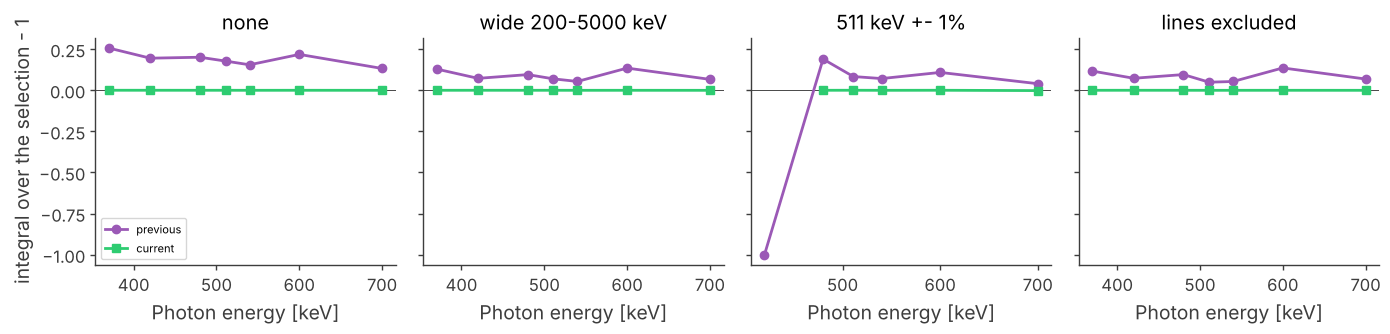

In [8]:
fig, axs = plt.subplots(1, len(cuts), figsize=(14, 3.5), sharey=True)
for ax, name in zip(axs, cuts):
    ax.axhline(0, color='k', lw=0.5)
    ax.plot(photon_energies, c_previous[name] - 1, 'o-', label='previous')
    ax.plot(photon_energies, c_current[name] - 1, 's-', label='current')
    ax.set_title(name)
    ax.set_xlabel('Photon energy [keV]')
axs[0].set_ylabel('integral over the selection - 1')
axs[0].legend()
fig.tight_layout()

The current version is normalized to the precision of the numerical integration
(a few 1e-4, from the midpoint rule in the `Phi`/`Theta` sub-bins), for every cut, including the narrow
511 keV window. The previous one is off by several percent, which the background would
amplify about 10 times in the Crab fits.

## Edges

The density at fixed `Phi`, `Theta` and `Zeta`, as a function of `Epsilon`, for a photon
at 511 keV. It now ramps linearly to zero between the outer `Epsilon` centers and the
edges (`fill_value=0` in `histpy`), instead of being held flat and cut off at the edges.


WARNING RuntimeWarning: invalid value encountered in divide



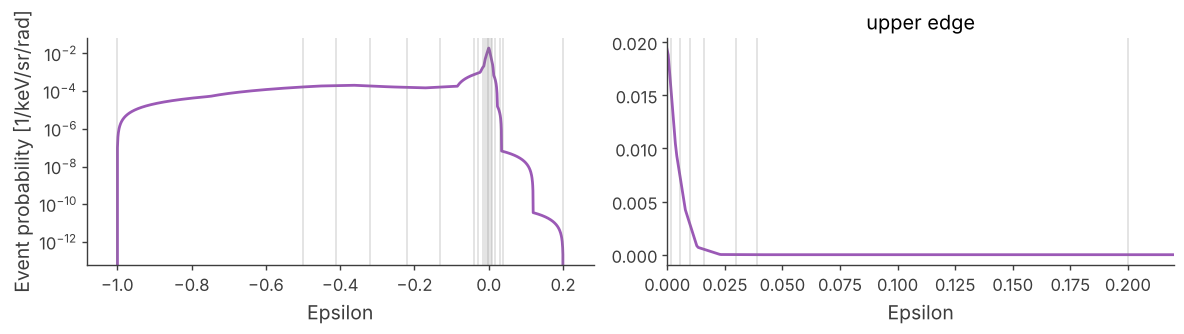

In [9]:
irf, aeff = load_slice()
model = IRFRelativeHistUnpolarized(irf, aeff=aeff, copy=False)

lon, lat, energy = photon_lon[3], photon_lat[3], 511.
phi, theta = np.deg2rad(55.), np.deg2rad(2.)
eps = np.linspace(-1.02, 0.22, 2000)
zeta = np.deg2rad(100.)


def density_at(model, eps, zeta):
    n = np.broadcast(eps, zeta).size
    direction = UnitSphericalRepresentation(lon=np.full(n, lon) * u.rad, lat=np.full(n, lat) * u.rad)
    relcoords = RelativeCDSCoordinates(direction.to_cartesian().xyz, model._pol_convention)
    psichi = UnitSphericalRepresentation.from_cartesian(CartesianRepresentation(
        *RelativeCDSCoordinates.to_cds(relcoords, np.full(n, phi + theta), np.broadcast_to(zeta, n)), unit=u.one))
    photons = photon_list(np.full(n, lon), np.full(n, lat), np.full(n, energy))
    events = event_list(psichi.lon.to_value(u.rad), psichi.lat.to_value(u.rad), np.full(n, phi),
                     energy * (1 + np.broadcast_to(eps, n)))
    return np.asarray(model.event_probability(photons, events))


fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(eps, density_at(model, eps, zeta))
axs[1].plot(eps, density_at(model, eps, zeta))
axs[1].set_xlim(0.0, 0.22)
for ax in axs:
    for x in model.axes['Epsilon'].edges:
        ax.axvline(x, color='gray', lw=0.3)
    ax.set_xlabel('Epsilon')
axs[0].set_ylabel('Event probability [1/keV/sr/rad]')
axs[0].set_yscale('log')
axs[1].set_title('upper edge')
fig.tight_layout()

And as a function of `Zeta`, across 0 / 360 deg: it is continuous, interpolating between
the last and first bins (`fill_value='periodic'`).

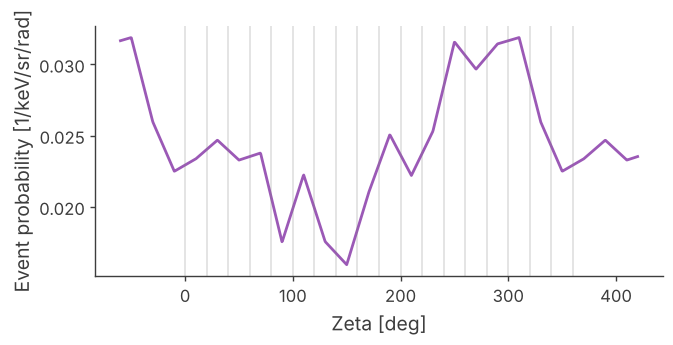

In [10]:
zeta = np.deg2rad(np.linspace(-60, 420, 1000))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.rad2deg(zeta), density_at(model, 0.0, zeta))
for x in np.rad2deg(model.axes['Zeta'].edges):
    ax.axvline(x, color='gray', lw=0.3)
ax.set_xlabel('Zeta [deg]')
ax.set_ylabel('Event probability [1/keV/sr/rad]')
fig.tight_layout()